<a href="https://colab.research.google.com/github/AlokChaudhary752/Trained-Model/blob/main/detectionmodel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install catboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import ipaddress
import re
import sqlite3 as sql
import time
import pickle
from sklearn.preprocessing import MinMaxScaler,StandardScaler,LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 61.1 MB/s  0:00:01


In [ ]:
import pandas as pd
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.impute import SimpleImputer

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/CyberSecurity_Dataset'))

['BCCC-CIRA-CIC-DoHBrw-2020.csv']


In [ ]:
folder_path ='/content/drive/MyDrive/CyberSecurity_Dataset'

print("Folder exists:", os.path.exists(folder_path))

Folder exists: True


In [ ]:
import pandas as pd

In [ ]:
import pandas as pd
file_path = '/content/drive/MyDrive/CyberSecurity_Dataset/BCCC-CIRA-CIC-DoHBrw-2020.csv'
df = pd.read_csv(file_path,nrows=1000, low_memory=False)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1000, 29)


In [ ]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['FlowBytesSent', 'FlowSentRate', 'FlowBytesReceived', 'FlowReceivedRate', 'PacketLengthVariance', 'PacketLengthStandardDeviation', 'PacketLengthMean', 'PacketLengthMedian', 'PacketLengthMode', 'PacketLengthSkewFromMedian', 'PacketLengthSkewFromMode', 'PacketLengthCoefficientofVariation', 'PacketTimeVariance', 'PacketTimeStandardDeviation', 'PacketTimeMean', 'PacketTimeMedian', 'PacketTimeMode', 'PacketTimeSkewFromMedian', 'PacketTimeSkewFromMode', 'PacketTimeCoefficientofVariation', 'ResponseTimeTimeVariance', 'ResponseTimeTimeStandardDeviation', 'ResponseTimeTimeMean', 'ResponseTimeTimeMedian', 'ResponseTimeTimeMode', 'ResponseTimeTimeSkewFromMedian', 'ResponseTimeTimeSkewFromMode', 'ResponseTimeTimeCoefficientofVariation', 'Label']


In [ ]:
import numpy as np
df.replace('?', np.nan, inplace=True)

print("Missing vvalues:")
print(df.isnull().sum().sort_values(ascending=False).head(20))

Missing vvalues:
FlowBytesSent                         0
FlowSentRate                          0
FlowBytesReceived                     0
FlowReceivedRate                      0
PacketLengthVariance                  0
PacketLengthStandardDeviation         0
PacketLengthMean                      0
PacketLengthMedian                    0
PacketLengthMode                      0
PacketLengthSkewFromMedian            0
PacketLengthSkewFromMode              0
PacketLengthCoefficientofVariation    0
PacketTimeVariance                    0
PacketTimeStandardDeviation           0
PacketTimeMean                        0
PacketTimeMedian                      0
PacketTimeMode                        0
PacketTimeSkewFromMedian              0
PacketTimeSkewFromMode                0
PacketTimeCoefficientofVariation      0
dtype: int64


In [ ]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 2


Text(0, 0.5, 'Total number of null value in each column')

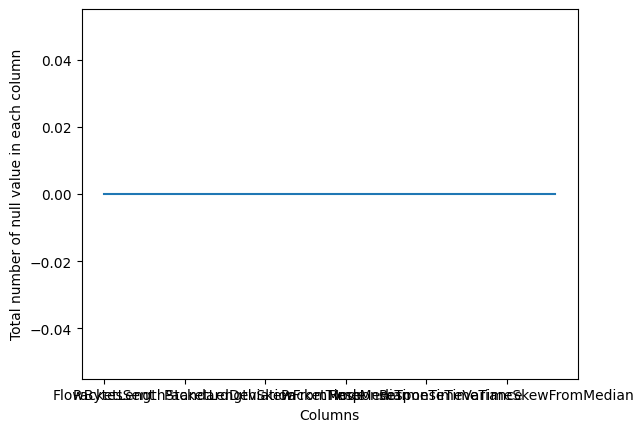

In [ ]:
pd.isnull(df).sum().plot()
plt.xlabel('Columns')
plt.ylabel('Total number of null value in each column')

Text(0, 0.5, 'Total number of null value in each column')

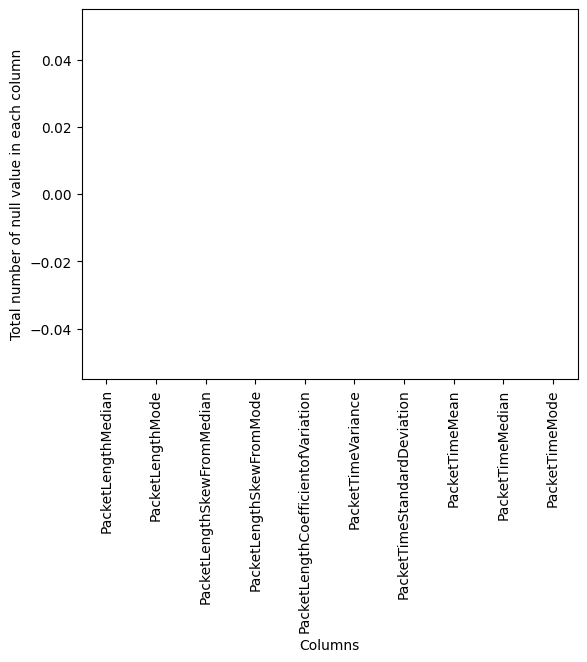

In [ ]:
pd.isnull(df).sum()[7:17].plot(kind='bar')
plt.xlabel('Columns')
plt.ylabel('Total number of null value in each column')

In [ ]:
df.head()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label
0,353,80.890348,393,90.056393,469.209877,21.661253,82.888889,66.0,66,2.339046,...,0.534524,1.754601e-09,0.000042,0.000048,0.000019,0.000017,2.028699,0.737490,0.869641,Benign
1,1807,53.056709,4828,141.758602,145520.370987,381.471324,228.793103,76.0,68,1.201609,...,1.591559,5.348911e-05,0.007314,0.011523,0.015273,0.000016,-1.538407,1.573304,0.634722,Malicious
2,15000,479.536009,27719,886.150575,25949.480963,161.088426,135.186709,87.0,87,0.897396,...,0.670950,3.356292e-01,0.579335,0.139518,0.001976,0.000003,0.712241,0.240819,4.152404,Malicious
3,1755,58.193065,4617,153.125406,154088.445853,392.541007,245.112953,75.5,54,1.296268,...,2.029971,1.245935e+02,11.162146,5.011613,0.015778,0.012884,1.342708,0.447829,2.227258,Benign
4,618,3.491495,315,1.779646,319.410000,17.872045,93.300000,105.0,105,-1.963961,...,0.816362,2.975575e-09,0.000054,0.015507,0.015471,0.015466,1.986391,0.751146,0.003502,Benign


In [ ]:
df.columns

Index(['FlowBytesSent', 'FlowSentRate', 'FlowBytesReceived',
       'FlowReceivedRate', 'PacketLengthVariance',
       'PacketLengthStandardDeviation', 'PacketLengthMean',
       'PacketLengthMedian', 'PacketLengthMode', 'PacketLengthSkewFromMedian',
       'PacketLengthSkewFromMode', 'PacketLengthCoefficientofVariation',
       'PacketTimeVariance', 'PacketTimeStandardDeviation', 'PacketTimeMean',
       'PacketTimeMedian', 'PacketTimeMode', 'PacketTimeSkewFromMedian',
       'PacketTimeSkewFromMode', 'PacketTimeCoefficientofVariation',
       'ResponseTimeTimeVariance', 'ResponseTimeTimeStandardDeviation',
       'ResponseTimeTimeMean', 'ResponseTimeTimeMedian',
       'ResponseTimeTimeMode', 'ResponseTimeTimeSkewFromMedian',
       'ResponseTimeTimeSkewFromMode',
       'ResponseTimeTimeCoefficientofVariation', 'Label'],
      dtype='object')

In [ ]:
import glob
import os
import pandas as pd
folder_path = '/content/drive/MyDrive/CyberSecurity_Dataset'
all_files = glob.glob(os.path.join(folder_path, '*.csv'))
df_list =[]
for file in all_files:
    df_temp = pd.read_csv(file, low_memory=False)
    df_list.append(df_temp)
if len(df_list)>0:
  df_combined = pd.concat(df_list, axis=0, ignore_index=True)
  print('\nTotal Rows & Columns:', df_combined.shape)
else:
  print('No CSV files found in the specified folder directory.')


Total Rows & Columns: (499106, 29)


In [ ]:
print(df_combined.shape)

(499106, 29)


In [ ]:
import glob
import os
import pandas as pd

# Corrected: Point to the directory containing the file instead of the file itself
folder_path = '/content/drive/MyDrive/CyberSecurity_Dataset'
all_files = glob.glob(os.path.join(folder_path, '*.csv'))

df_list = []
for file in all_files:
  df_temp = pd.read_csv(file, low_memory=False)
  df_list.append(df_temp)

# Variable ka naam seedha 'df' rakhein
if len(df_list) > 0:
  df = pd.concat(df_list, axis=0, ignore_index=True)
  print('Final Shape:', df.shape)
else:
  print('No CSV files found in:', folder_path)


Final Shape: (499106, 29)


In [ ]:
df['FlowSentRate'].nunique()

473663

In [ ]:
df["Label"].value_counts()

,count
Label,
Benign,249553
Malicious,249553


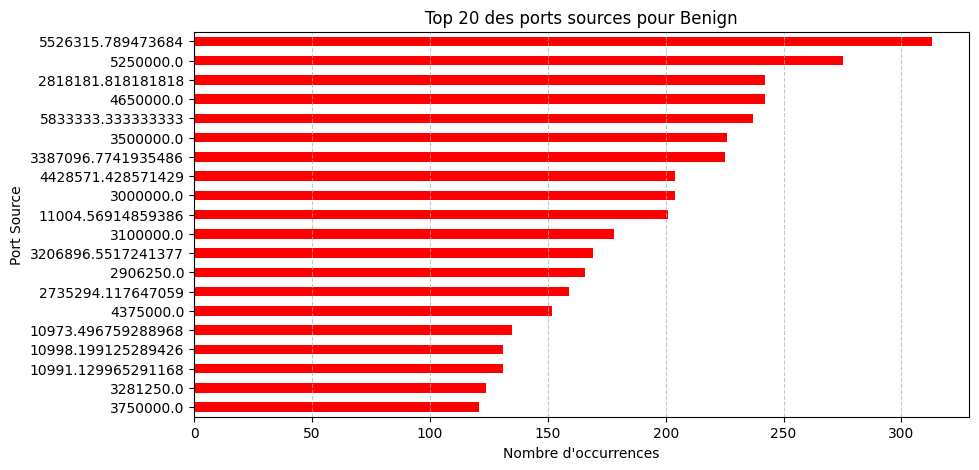

In [ ]:
attack_type = "Benign"


df_filtered = df[df['Label'] == attack_type]

port_counts = df_filtered['FlowSentRate'].value_counts()

top_ports = port_counts.head(20)

plt.figure(figsize=(10, 5))
top_ports.plot(kind='barh', color='red')

plt.title(f"Top 20 des ports sources pour {attack_type}")
plt.xlabel("Nombre d'occurrences")
plt.ylabel("Port Source")
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

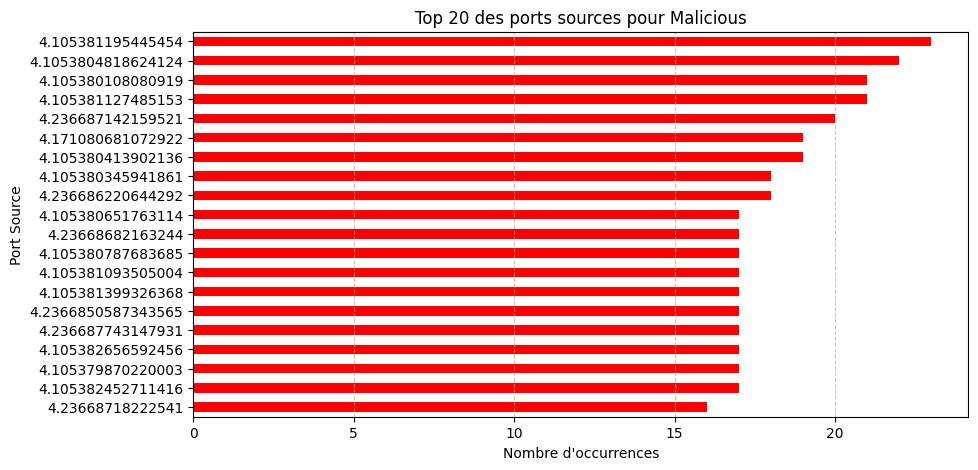

In [ ]:
attack_type = "Malicious"


df_filtered = df[df['Label'] == attack_type]

port_counts = df_filtered['FlowSentRate'].value_counts()

top_ports = port_counts.head(20)

plt.figure(figsize=(10, 5))
top_ports.plot(kind='barh', color='red')

plt.title(f"Top 20 des ports sources pour {attack_type}")
plt.xlabel("Nombre d'occurrences")
plt.ylabel("Port Source")
plt.gca().invert_yaxis()
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.show()

In [ ]:
df.isnull().sum()

,0
FlowBytesSent,0
FlowSentRate,0
FlowBytesReceived,0
FlowReceivedRate,0
PacketLengthVariance,0
PacketLengthStandardDeviation,0
PacketLengthMean,0
PacketLengthMedian,0
PacketLengthMode,0
PacketLengthSkewFromMedian,0


In [ ]:
df.describe()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,FlowReceivedRate,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,...,PacketTimeSkewFromMode,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMedian,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation
count,4.991060e+05,4.991060e+05,4.991060e+05,4.991060e+05,4.991060e+05,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,...,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000
mean,4.020093e+04,4.733915e+04,4.250156e+04,3.166829e+04,9.263585e+04,220.169083,173.159814,95.472702,70.749953,0.442934,...,1.246052,0.972995,1.711825,0.319586,0.442021,0.394671,0.205894,-0.968984,-0.060800,1.114611
std,1.439617e+05,4.212751e+05,1.393927e+05,2.566805e+05,1.534938e+05,210.141825,85.506490,32.999740,14.830277,1.551998,...,0.713803,0.520212,11.106412,1.244031,2.071807,2.351233,1.724873,3.163775,3.198770,1.735820
min,5.500000e+01,1.464903e+00,5.400000e+01,1.576245e+00,0.000000e+00,0.000000,56.000000,54.000000,54.000000,-10.000000,...,-5.265523,0.077182,0.000000,0.000000,0.000005,0.000002,-0.000001,-10.000000,-10.000000,0.000000
25%,6.180000e+02,5.410781e+01,4.760000e+02,1.418128e+02,4.692099e+02,21.661253,92.000000,76.000000,66.000000,0.199848,...,0.627988,0.577836,0.000021,0.004454,0.010538,0.012238,0.000016,-1.797168,0.393686,0.552687
50%,1.807000e+03,3.640969e+02,4.827000e+03,4.611146e+02,1.826789e+04,135.142971,152.488283,87.000000,68.000000,0.986397,...,1.224949,0.748184,0.000079,0.008820,0.015148,0.015407,0.000034,0.000000,0.908002,0.800649
75%,5.542000e+03,3.810260e+03,7.888000e+03,4.215498e+03,1.415989e+05,376.296309,228.758621,105.000000,68.000000,1.201609,...,1.716577,1.516263,0.000357,0.018640,0.024903,0.016300,0.015161,0.936908,1.305393,1.208105
max,8.015359e+06,2.304348e+07,7.723184e+06,7.600000e+06,1.578115e+06,1256.230616,689.800000,317.000000,553.000000,2.932375,...,12.956406,5.616085,647.245330,25.441017,28.017596,28.017596,28.017596,2.970716,5.428781,66.309747


In [ ]:
df.duplicated().sum()

np.int64(7115)

In [ ]:
df.nunique()

,0
FlowBytesSent,92881
FlowSentRate,473663
FlowBytesReceived,97046
FlowReceivedRate,475526
PacketLengthVariance,204248
PacketLengthStandardDeviation,204015
PacketLengthMean,196341
PacketLengthMedian,32083
PacketLengthMode,165
PacketLengthSkewFromMedian,203906


In [ ]:
num_cols = df.select_dtypes(include=['float64', 'int64']).columns

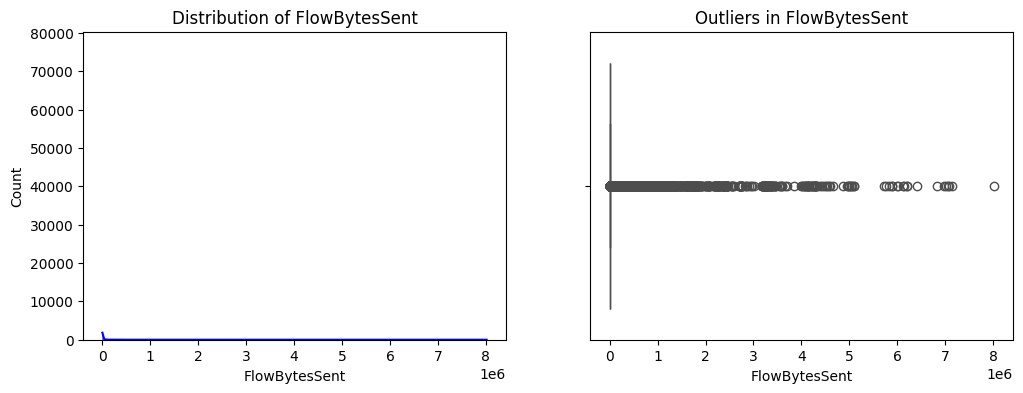

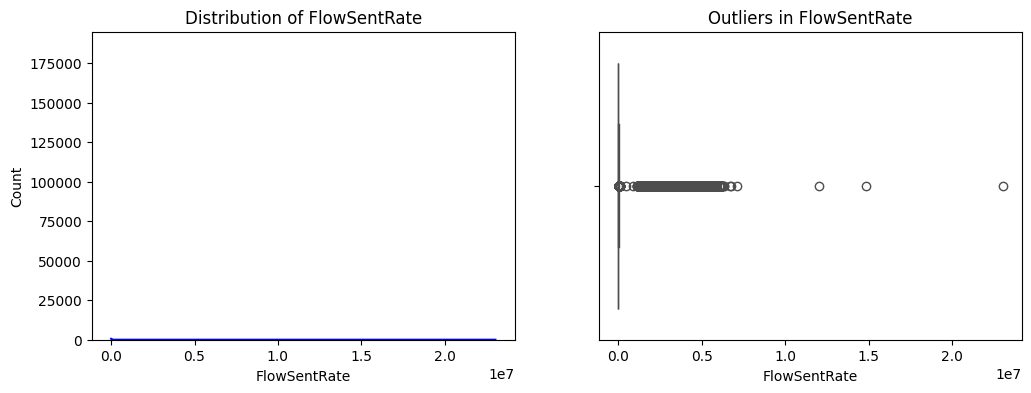

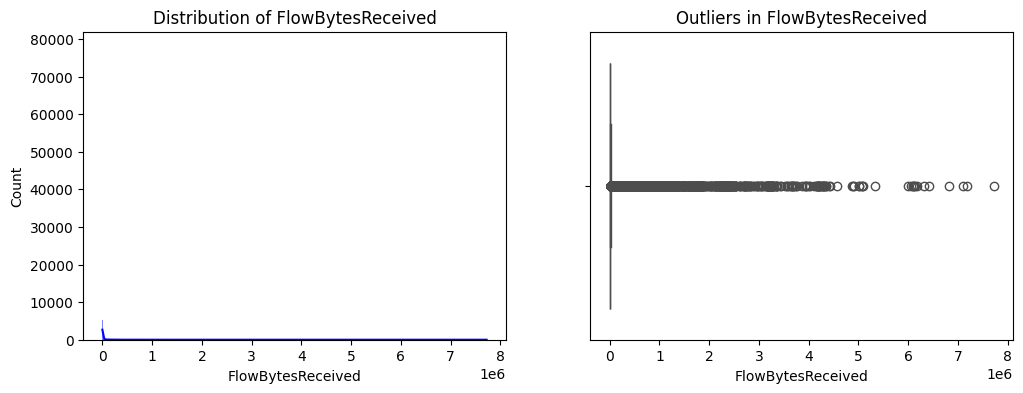

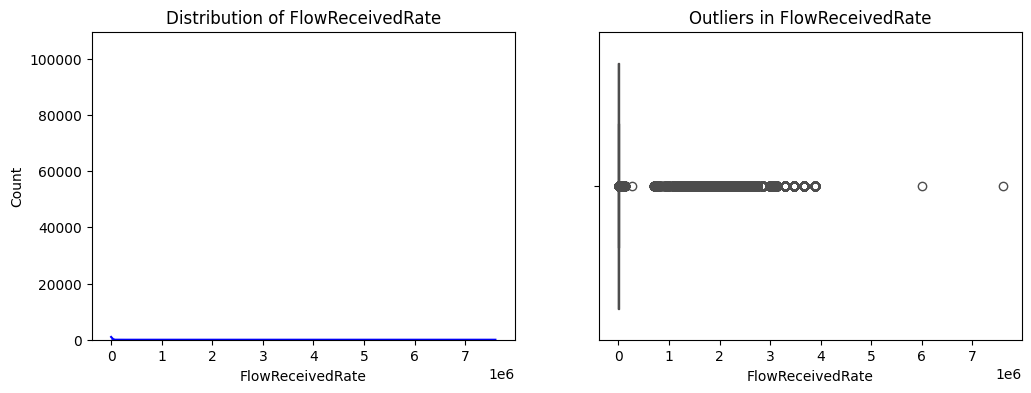

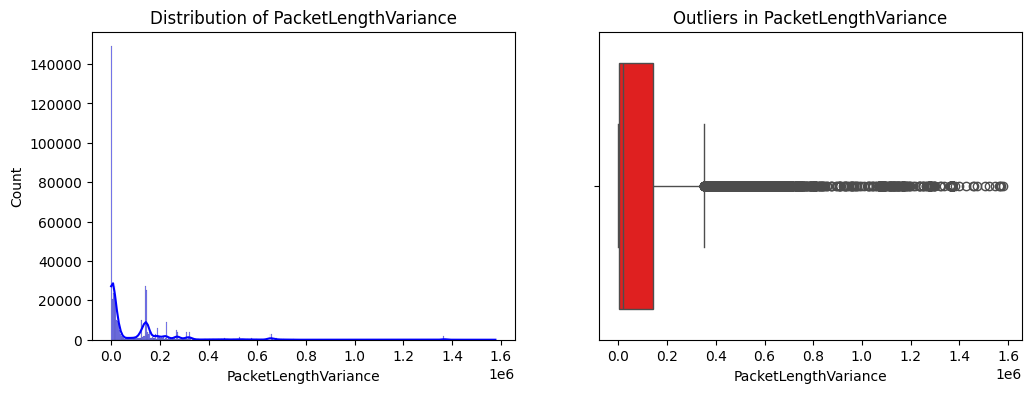

In [ ]:
for col in num_cols[:5]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(df[col], kde=True, ax=axes[0], color='blue')
    axes[0].set_title(f'Distribution of {col}')

    sns.boxplot(x=df[col], ax=axes[1], color='red')
    axes[1].set_title(f'Outliers in {col}')

    plt.show()

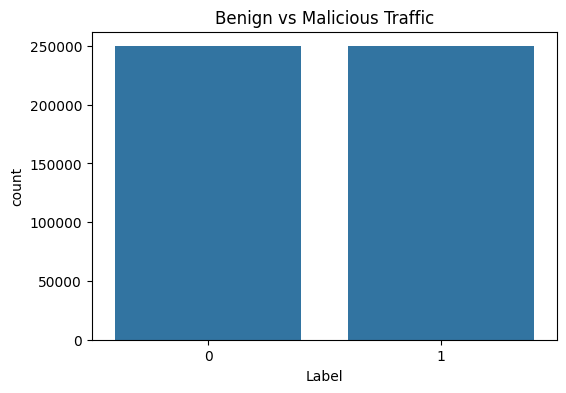

In [112]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Label', data=df)
plt.title('Benign vs Malicious Traffic')
plt.show()


In [ ]:
counts = df['Label'].value_counts()
percent = df['Label'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': counts, 'Percentage': percent}))

            Count  Percentage
Label                        
Benign     249553        50.0
Malicious  249553        50.0


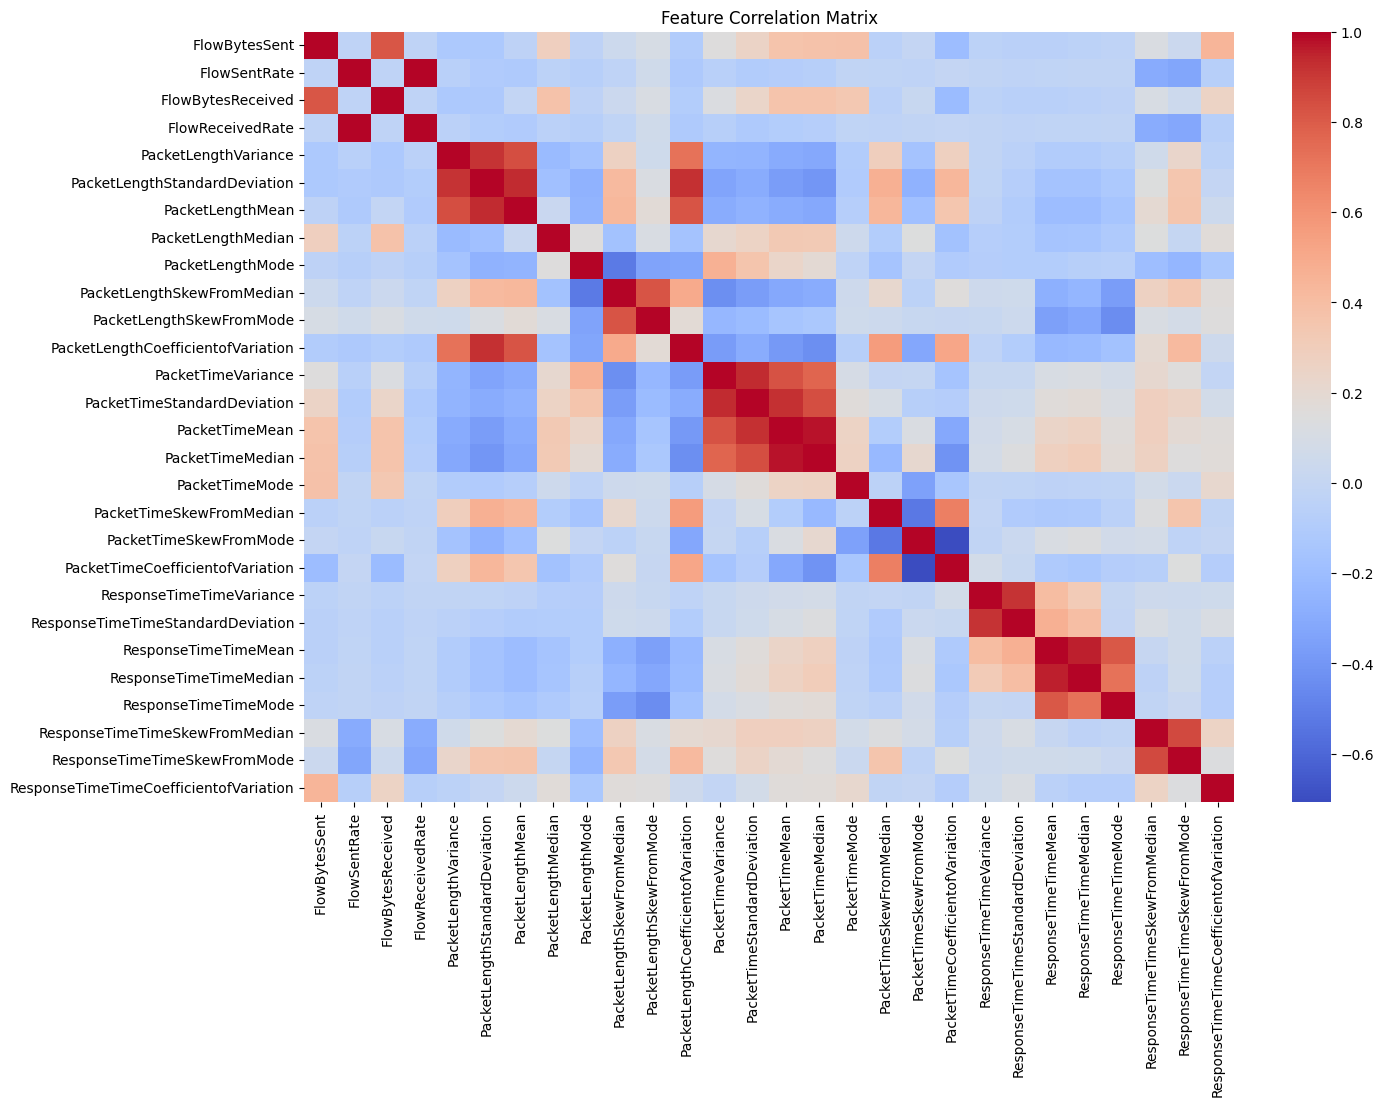

In [ ]:
plt.figure(figsize=(15, 10))
corr = df.select_dtypes(include=[np.number]).corr()
sns.heatmap(corr, annot=False, cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.show()


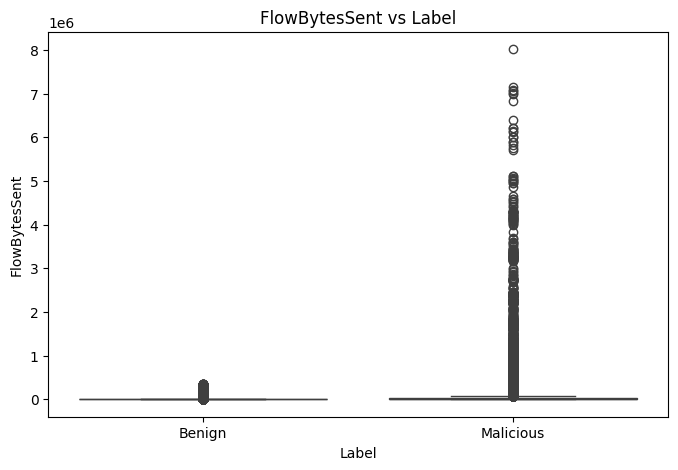

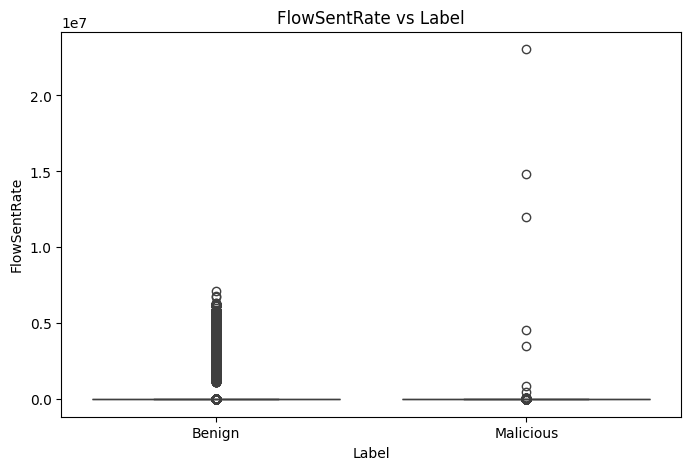

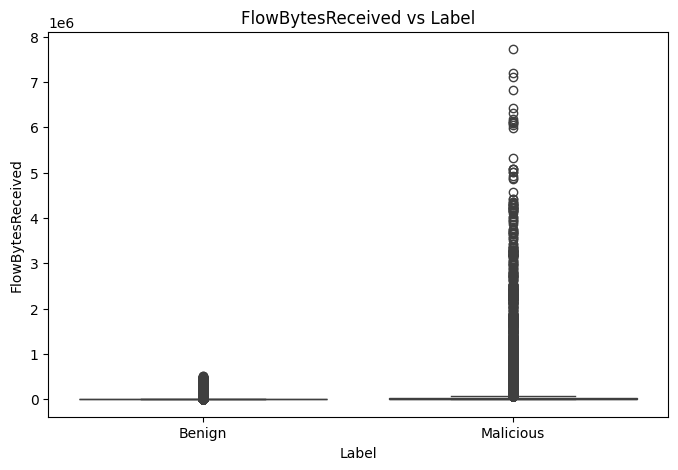

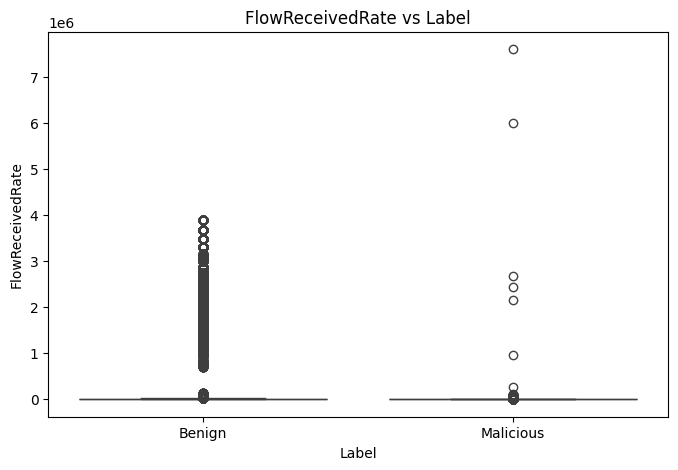

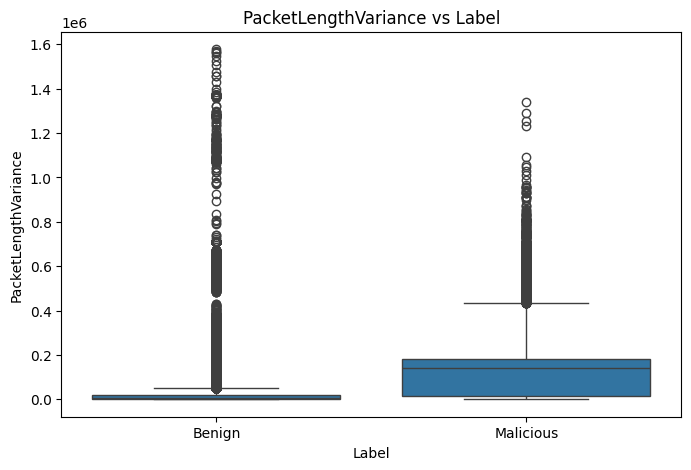

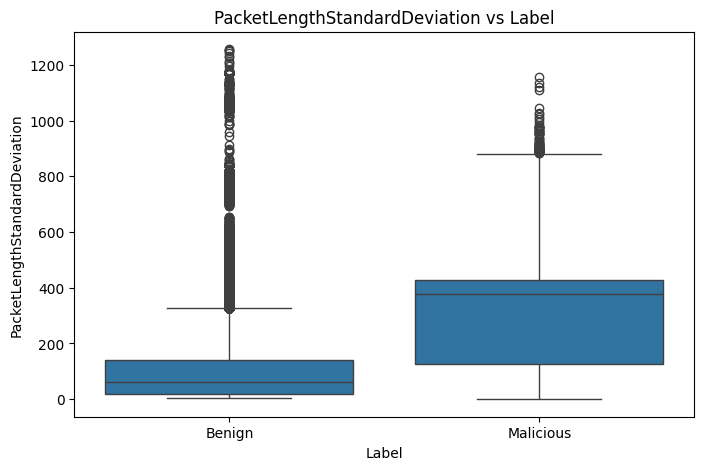

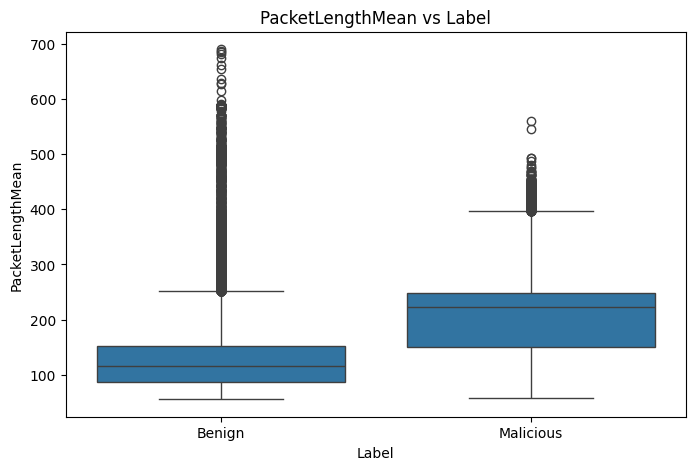

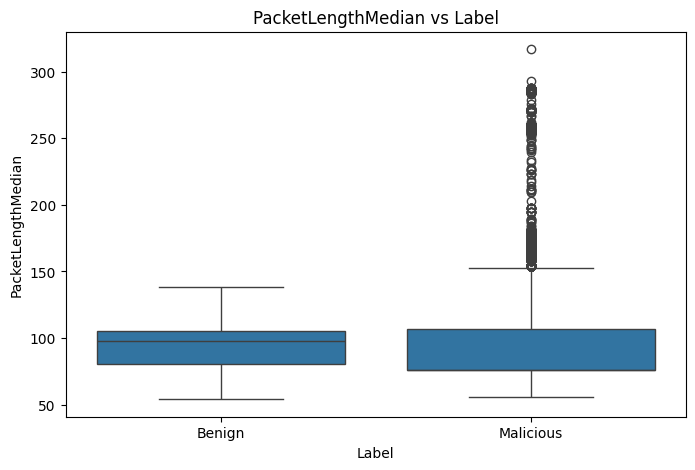

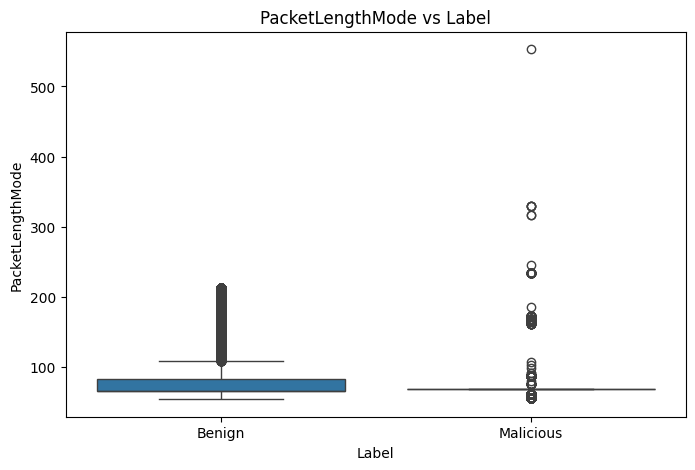

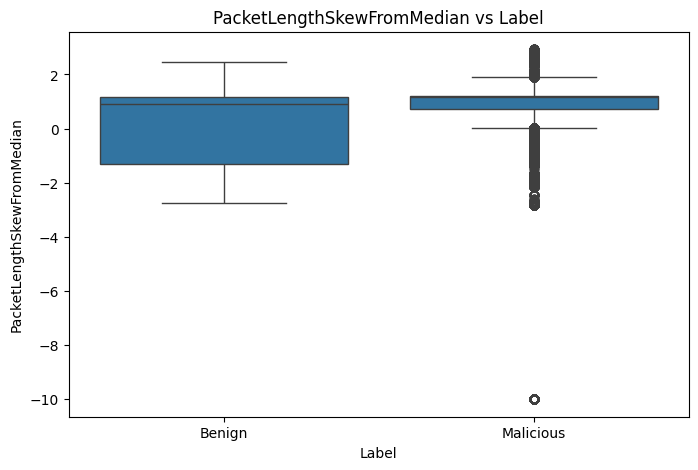

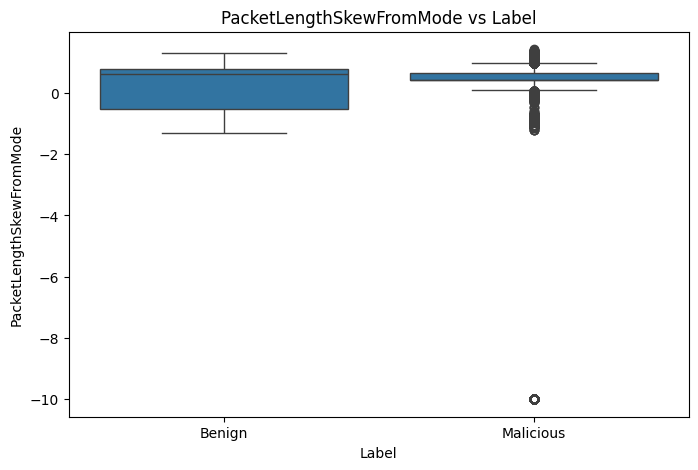

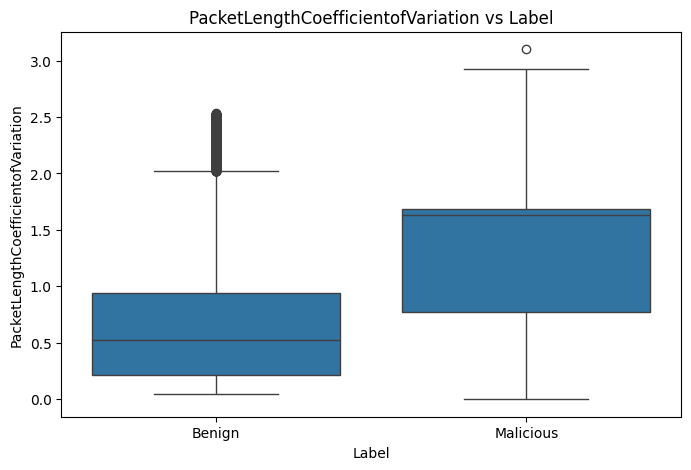

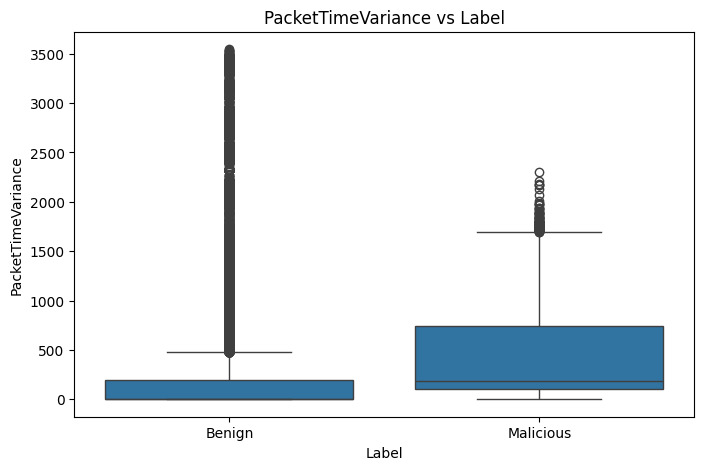

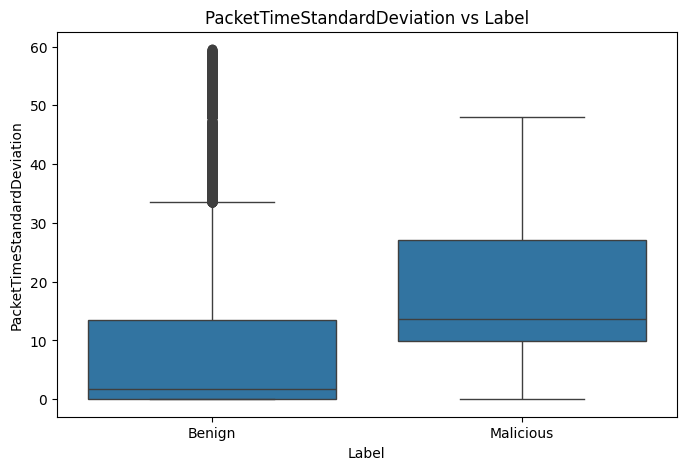

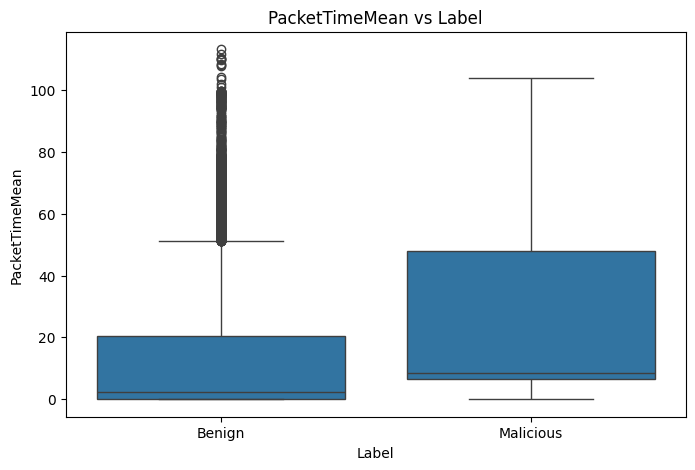

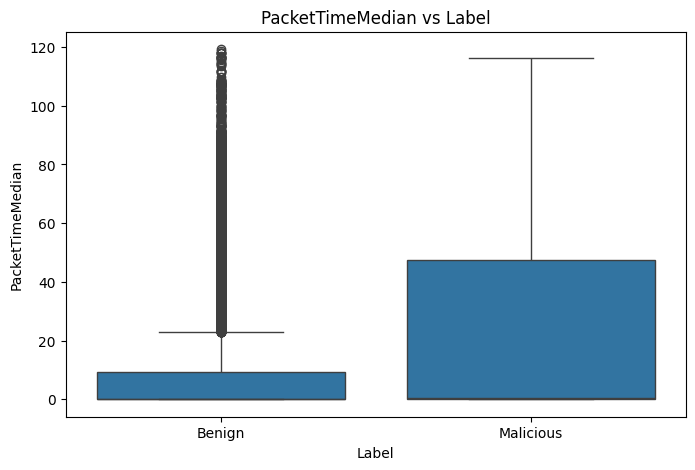

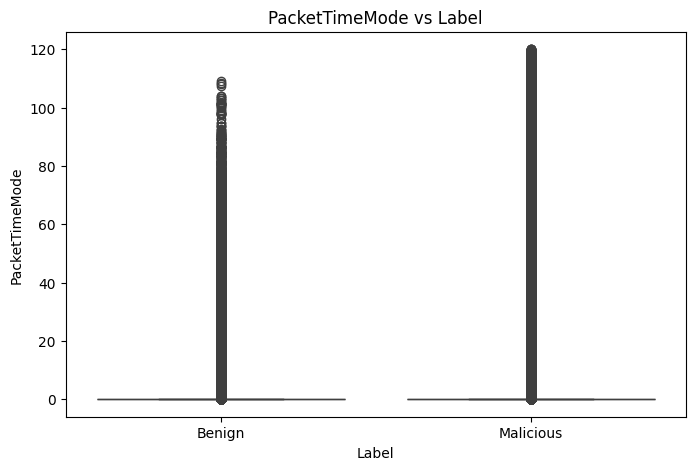

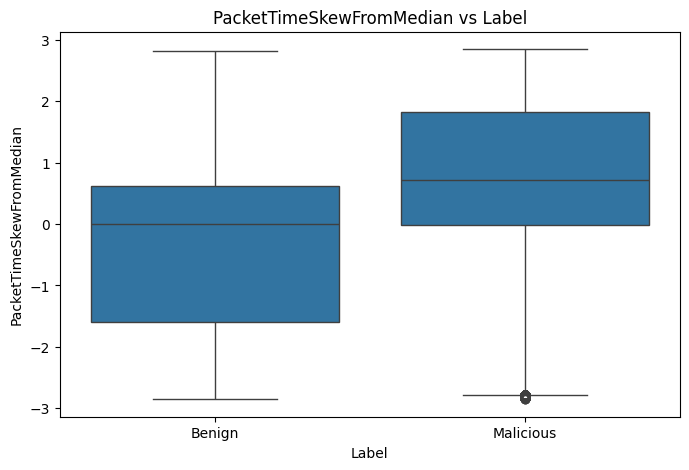

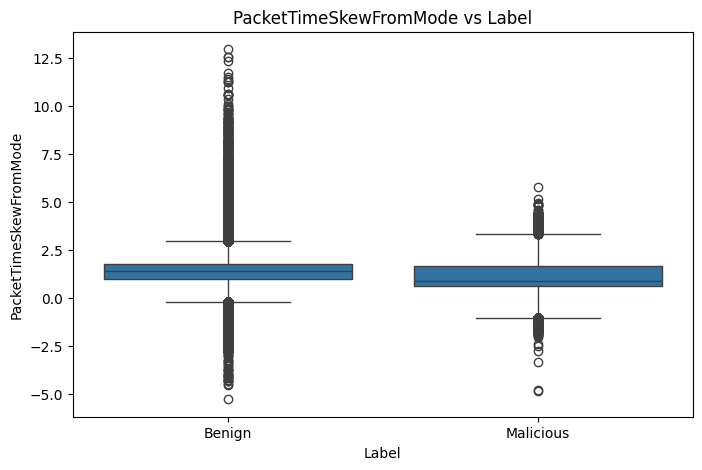

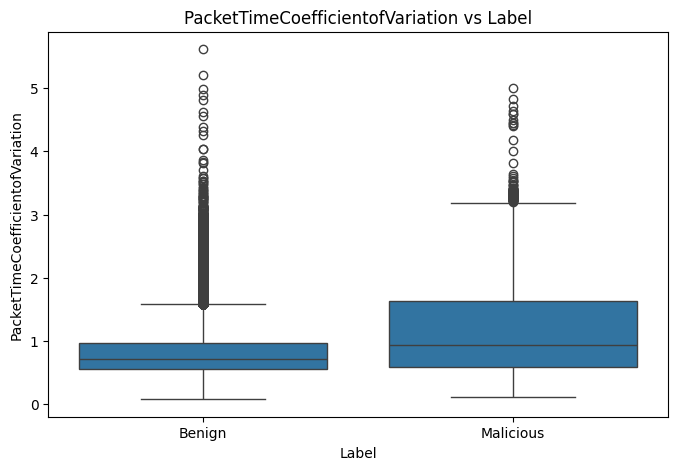

In [ ]:
important_features = num_cols[:20]
for col in important_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(x='Label', y=col, data=df)
    plt.title(f'{col} vs Label')
    plt.show()

In [ ]:
cat_cols = df.select_dtypes(include=['object']).columns
print("Categorical Columns:", cat_cols)

Categorical Columns: Index(['Label'], dtype='object')


In [ ]:
df.isnull().sum()

,0
FlowBytesSent,0
FlowSentRate,0
FlowBytesReceived,0
FlowReceivedRate,0
PacketLengthVariance,0
PacketLengthStandardDeviation,0
PacketLengthMean,0
PacketLengthMedian,0
PacketLengthMode,0
PacketLengthSkewFromMedian,0


In [ ]:
inf_counts = np.isinf(df).sum()

TypeError: ufunc 'isinf' not supported for the input types, and the inputs could not be safely coerced to any supported types according to the casting rule ''safe''

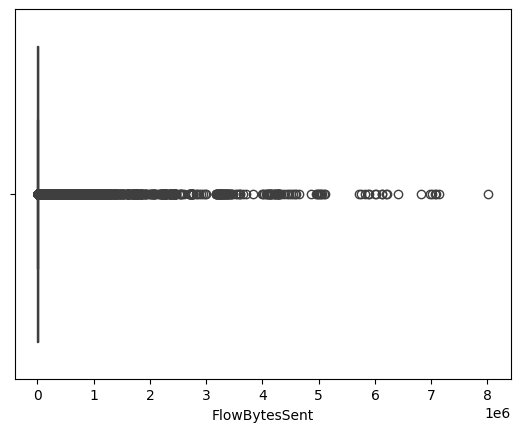

In [ ]:
sns.boxplot(x=df['FlowBytesSent'])
plt.show()

In [ ]:
Q1 = df['FlowBytesSent'].quantile(0.25)
Q3 = df['FlowBytesSent'].quantile(0.75)
IQR = Q3 - Q1

In [ ]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound}")
print(f"Upper Bound: {upper_bound}")

Lower Bound: -6768.0
Upper Bound: 12928.0


In [ ]:
df['FlowBytesSent_log']=np.log(df['FlowBytesSent'])


In [ ]:
df['FlowBytesSent'] = np.where(df['FlowBytesSent'] > upper_bound, upper_bound,
                               np.where(df['FlowBytesSent'] < lower_bound, lower_bound, df['FlowBytesSent']))

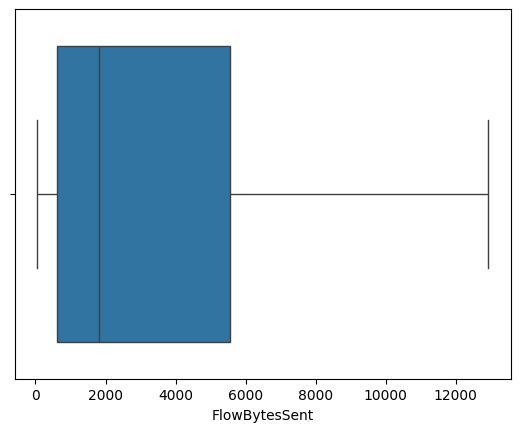

In [ ]:
sns.boxplot(x=df['FlowBytesSent'])
plt.show()

In [ ]:
print(df.select_dtypes(include=['object']).columns)

Index(['Label'], dtype='object')


In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['Label'] = le.fit_transform(df['Label'])

In [ ]:
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Mapping: {mapping}")

Mapping: {'Benign': np.int64(0), 'Malicious': np.int64(1)}


In [ ]:
print(df.columns.tolist())

['FlowBytesSent', 'FlowSentRate', 'FlowBytesReceived', 'FlowReceivedRate', 'PacketLengthVariance', 'PacketLengthStandardDeviation', 'PacketLengthMean', 'PacketLengthMedian', 'PacketLengthMode', 'PacketLengthSkewFromMedian', 'PacketLengthSkewFromMode', 'PacketLengthCoefficientofVariation', 'PacketTimeVariance', 'PacketTimeStandardDeviation', 'PacketTimeMean', 'PacketTimeMedian', 'PacketTimeMode', 'PacketTimeSkewFromMedian', 'PacketTimeSkewFromMode', 'PacketTimeCoefficientofVariation', 'ResponseTimeTimeVariance', 'ResponseTimeTimeStandardDeviation', 'ResponseTimeTimeMean', 'ResponseTimeTimeMedian', 'ResponseTimeTimeMode', 'ResponseTimeTimeSkewFromMedian', 'ResponseTimeTimeSkewFromMode', 'ResponseTimeTimeCoefficientofVariation', 'Label', 'FlowBytesSent_log']


In [ ]:
print(df.select_dtypes(include=['object', 'category']).columns.tolist())

[]


In [ ]:
print(df.dtypes)
print(df['Label'].value_counts())

FlowBytesSent                             float64
FlowSentRate                              float64
FlowBytesReceived                           int64
FlowReceivedRate                          float64
PacketLengthVariance                      float64
PacketLengthStandardDeviation             float64
PacketLengthMean                          float64
PacketLengthMedian                        float64
PacketLengthMode                            int64
PacketLengthSkewFromMedian                float64
PacketLengthSkewFromMode                  float64
PacketLengthCoefficientofVariation        float64
PacketTimeVariance                        float64
PacketTimeStandardDeviation               float64
PacketTimeMean                            float64
PacketTimeMedian                          float64
PacketTimeMode                            float64
PacketTimeSkewFromMedian                  float64
PacketTimeSkewFromMode                    float64
PacketTimeCoefficientofVariation          float64


In [ ]:
print(df.select_dtypes(include=['object', 'category']).columns.tolist())

[]


In [ ]:
print(df.isnull().sum().sum())

0


In [ ]:
import numpy as np

numeric_df = df.select_dtypes(include=np.number)

print("Positive/Negative Infinity:")
print(np.isinf(numeric_df).sum().sum())

Positive/Negative Infinity:
0


In [ ]:
X = df.drop(columns=['Label'])
y = df['Label']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (499106, 29)
Target shape: (499106,)


In [ ]:
import numpy as np

print("Dataset Shape:", df.shape)

print("Missing Values:", df.isnull().sum().sum())

numeric_df = df.select_dtypes(include=np.number)
print("Infinite Values:", np.isinf(numeric_df).sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

Dataset Shape: (499106, 30)
Missing Values: 0
Infinite Values: 0
Duplicate Rows: 7115


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499106 entries, 0 to 499105
Data columns (total 30 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   FlowBytesSent                           499106 non-null  float64
 1   FlowSentRate                            499106 non-null  float64
 2   FlowBytesReceived                       499106 non-null  int64  
 3   FlowReceivedRate                        499106 non-null  float64
 4   PacketLengthVariance                    499106 non-null  float64
 5   PacketLengthStandardDeviation           499106 non-null  float64
 6   PacketLengthMean                        499106 non-null  float64
 7   PacketLengthMedian                      499106 non-null  float64
 8   PacketLengthMode                        499106 non-null  int64  
 9   PacketLengthSkewFromMedian              499106 non-null  float64
 10  PacketLengthSkewFromMode                4991

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df.drop('Label', axis=1)
y = df['Label']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.preprocessing import RobustScaler

In [ ]:
scaler = RobustScaler()

In [ ]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
import pandas as pd
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
print(X_train_scaled_df.describe().loc[['min', 'max']])

     FlowBytesSent  FlowSentRate  FlowBytesReceived  FlowReceivedRate  \
min      -0.355736     -0.096194          -0.643782         -0.112564   
max       2.258071   3939.941824        1041.051659       1472.934067   

     PacketLengthVariance  PacketLengthStandardDeviation  PacketLengthMean  \
min             -0.129496                      -0.381171         -0.705796   
max             11.052525                       3.161148          3.928647   

     PacketLengthMedian  PacketLengthMode  PacketLengthSkewFromMedian  ...  \
min           -1.137931              -7.0                  -10.998370  ...   
max            7.931034             242.5                    1.948099  ...   

     PacketTimeCoefficientofVariation  ResponseTimeTimeVariance  \
min                         -0.714589             -2.340455e-01   
max                          4.751236              1.932159e+06   

     ResponseTimeTimeStandardDeviation  ResponseTimeTimeMean  \
min                          -0.622529      

In [ ]:
constant_cols = [col for col in df.columns if df[col].nunique()<=1]
print(f"Constant colums to  drop:{constant_cols}")

Constant colums to  drop:[]


In [ ]:
df.drop(columns=constant_cols, inplace=True)

In [ ]:
corr_matrix = df.corr().abs()

In [ ]:
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))


In [ ]:
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

In [ ]:
print(f"Highly corrrlated columns to drop: {to_drop}")

Highly corrrlated columns to drop: ['FlowReceivedRate', 'PacketTimeMedian', 'ResponseTimeTimeMedian']


In [ ]:
df.drop(columns=to_drop, inplace=True)

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

In [ ]:
model =RandomForestClassifier()
model.fit(X_train,y_train)

RandomForestClassifier()

In [ ]:
importances = model.feature_importances_
feature_names = X.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

In [ ]:
print(feature_importance_df.head(10))

                               Feature  Importance
8                     PacketLengthMode    0.225983
5        PacketLengthStandardDeviation    0.082548
6                     PacketLengthMean    0.075419
7                   PacketLengthMedian    0.068681
2                    FlowBytesReceived    0.061134
14                      PacketTimeMean    0.056136
13         PacketTimeStandardDeviation    0.053426
12                  PacketTimeVariance    0.043320
11  PacketLengthCoefficientofVariation    0.041547
4                 PacketLengthVariance    0.041021


In [ ]:

X = df.drop('Label', axis=1)


y = df['Label']



In [ ]:
print(df['Label'].value_counts(normalize=True)*100)

Label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('Label', axis=1)
y = df['Label']

In [ ]:
print("Training set ratio:\n",y_train.value_counts(normalize=True)*100)
print("Testing set ratio:\n",y_test.value_counts(normalize=True)*100)

Training set ratio:
 Label
1    50.004508
0    49.995492
Name: proportion, dtype: float64
Testing set ratio:
 Label
0    50.018032
1    49.981968
Name: proportion, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Split Completed Successfully!")

Split Completed Successfully!


In [ ]:
print(f"Total samples:{len(X)}")
print(f"Training samples:{len(X_train)}")
print(f"Testing samples:{len(X_test)}")

Total samples:499106
Training samples:399284
Testing samples:99822


In [ ]:
print("\nTraining Set Ratio:\n", y_train.value_counts(normalize=True) * 100)
print("\nTesting Set Ratio:\n", y_test.value_counts(normalize=True) * 100)


Training Set Ratio:
 Label
1    50.0
0    50.0
Name: proportion, dtype: float64

Testing Set Ratio:
 Label
0    50.0
1    50.0
Name: proportion, dtype: float64


In [ ]:
df.shape

(499106, 27)

In [ ]:
df.head()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,PacketLengthSkewFromMode,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label,FlowBytesSent_log
0,353.0,80.890348,393,469.209877,21.661253,82.888889,66.0,66,2.339046,0.779682,...,0.534524,1.754601e-09,0.000042,0.000048,0.000017,2.028699,0.737490,0.869641,0,5.866468
1,1807.0,53.056709,4828,145520.370987,381.471324,228.793103,76.0,68,1.201609,0.421508,...,1.591559,5.348911e-05,0.007314,0.011523,0.000016,-1.538407,1.573304,0.634722,1,7.499423
2,12928.0,479.536009,27719,25949.480963,161.088426,135.186709,87.0,87,0.897396,0.299132,...,0.670950,3.356292e-01,0.579335,0.139518,0.000003,0.712241,0.240819,4.152404,1,9.615805
3,1755.0,58.193065,4617,154088.445853,392.541007,245.112953,75.5,54,1.296268,0.486861,...,2.029971,1.245935e+02,11.162146,5.011613,0.012884,1.342708,0.447829,2.227258,0,7.470224
4,618.0,3.491495,315,319.410000,17.872045,93.300000,105.0,105,-1.963961,-0.654654,...,0.816362,2.975575e-09,0.000054,0.015507,0.015466,1.986391,0.751146,0.003502,0,6.426488


In [ ]:
df.tail()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,PacketLengthSkewFromMode,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label,FlowBytesSent_log
499101,4865.0,144.950072,7622,216676.627229,465.485367,231.240741,149.5,68,0.526810,0.350689,...,1.916871,6.745692e-05,0.008213,0.009261,0.000003,-1.093069,1.127264,0.886816,1,8.489822
499102,1807.0,53.007877,4895,141408.773333,376.043579,223.400000,76.0,68,1.175928,0.413250,...,1.629455,5.509494e-05,0.007423,0.010499,0.000021,-1.938720,1.411665,0.706966,1,7.499423
499103,1738.0,51.137163,4761,322424.727023,567.824557,240.703704,76.0,68,0.870183,0.304150,...,1.515189,5.126219e-05,0.007160,0.012407,0.000011,-1.628476,1.731273,0.577098,1,7.460490
499104,353.0,85.910364,393,469.209877,21.661253,82.888889,66.0,66,2.339046,0.779682,...,0.534526,2.246325e-09,0.000047,0.000051,0.000017,2.089574,0.717636,0.921984,0,5.866468
499105,4184.0,13011.997082,5406,13741.344067,117.222620,144.264302,105.0,66,1.004673,0.667596,...,0.528666,9.335833e-05,0.009620,0.015714,0.000018,-1.077359,1.618330,0.621961,0,8.339023


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 499106 entries, 0 to 499105
Data columns (total 27 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   FlowBytesSent                           499106 non-null  float64
 1   FlowSentRate                            499106 non-null  float64
 2   FlowBytesReceived                       499106 non-null  int64  
 3   PacketLengthVariance                    499106 non-null  float64
 4   PacketLengthStandardDeviation           499106 non-null  float64
 5   PacketLengthMean                        499106 non-null  float64
 6   PacketLengthMedian                      499106 non-null  float64
 7   PacketLengthMode                        499106 non-null  int64  
 8   PacketLengthSkewFromMedian              499106 non-null  float64
 9   PacketLengthSkewFromMode                499106 non-null  float64
 10  PacketLengthCoefficientofVariation      4991

In [ ]:
df.describe()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,PacketLengthSkewFromMode,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label,FlowBytesSent_log
count,499106.000000,4.991060e+05,4.991060e+05,4.991060e+05,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,...,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000,499106.000000
mean,4162.183644,4.733915e+04,4.250156e+04,9.263585e+04,220.169083,173.159814,95.472702,70.749953,0.442934,0.332692,...,0.972995,1.711825,0.319586,0.442021,0.205894,-0.968984,-0.060800,1.114611,0.500000,7.913719
std,4865.685622,4.212751e+05,1.393927e+05,1.534938e+05,210.141825,85.506490,32.999740,14.830277,1.551998,1.115806,...,0.520212,11.106412,1.244031,2.071807,1.724873,3.163775,3.198770,1.735820,0.500001,2.134518
min,55.000000,1.464903e+00,5.400000e+01,0.000000e+00,0.000000,56.000000,54.000000,54.000000,-10.000000,-10.000000,...,0.077182,0.000000,0.000000,0.000005,-0.000001,-10.000000,-10.000000,0.000000,0.000000,4.007333
25%,618.000000,5.410781e+01,4.760000e+02,4.692099e+02,21.661253,92.000000,76.000000,66.000000,0.199848,0.410528,...,0.577836,0.000021,0.004454,0.010538,0.000016,-1.797168,0.393686,0.552687,0.000000,6.426488
50%,1807.000000,3.640969e+02,4.827000e+03,1.826789e+04,135.142971,152.488283,87.000000,68.000000,0.986397,0.480897,...,0.748184,0.000079,0.008820,0.015148,0.000034,0.000000,0.908002,0.800649,0.500000,7.499423
75%,5542.000000,3.810260e+03,7.888000e+03,1.415989e+05,376.296309,228.758621,105.000000,68.000000,1.201609,0.707531,...,1.516263,0.000357,0.018640,0.024903,0.015161,0.936908,1.305393,1.208105,1.000000,8.620111
max,12928.000000,2.304348e+07,7.723184e+06,1.578115e+06,1256.230616,689.800000,317.000000,553.000000,2.932375,1.426177,...,5.616085,647.245330,25.441017,28.017596,28.017596,2.970716,5.428781,66.309747,1.000000,15.896870


In [ ]:
df.isnull().sum()

,0
FlowBytesSent,0
FlowSentRate,0
FlowBytesReceived,0
PacketLengthVariance,0
PacketLengthStandardDeviation,0
PacketLengthMean,0
PacketLengthMedian,0
PacketLengthMode,0
PacketLengthSkewFromMedian,0
PacketLengthSkewFromMode,0


In [ ]:
df.duplicated().sum()

np.int64(7115)

In [ ]:
df.nunique()

,0
FlowBytesSent,11503
FlowSentRate,473663
FlowBytesReceived,97046
PacketLengthVariance,204248
PacketLengthStandardDeviation,204015
PacketLengthMean,196341
PacketLengthMedian,32083
PacketLengthMode,165
PacketLengthSkewFromMedian,203906
PacketLengthSkewFromMode,203912


In [ ]:
df['Label'].value_counts()

,count
Label,
0,249553
1,249553


In [ ]:
df['Label'].value_counts(normalize=True)

,proportion
Label,
0,0.5
1,0.5


<Axes: >

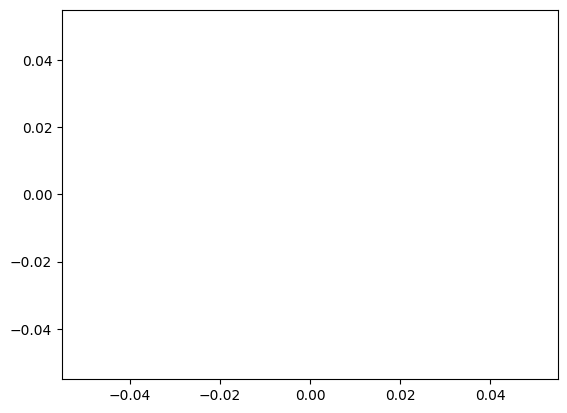

In [ ]:
sns.histplot()

<Axes: >

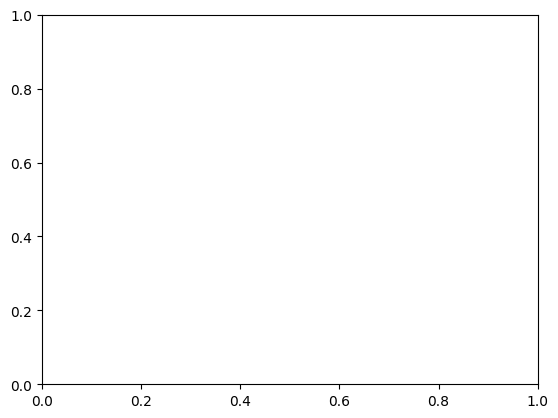

In [ ]:
sns.kdeplot()

In [ ]:
feature = 'FlowBytesSent'
print(f"Mean: {df[feature].mean()}")
print(f"Median: {df[feature].median()}")
print(f"Standard Deviation: {df[feature].std()}")
print(f"Skewness: {df[feature].skew()}")
print(f"Kurtosis: {df[feature].kurtosis()}")

Mean: 4162.183644356109
Median: 1807.0
Standard Deviation: 4865.685621661134
Skewness: 1.0936702439247612
Kurtosis: -0.565667060715791


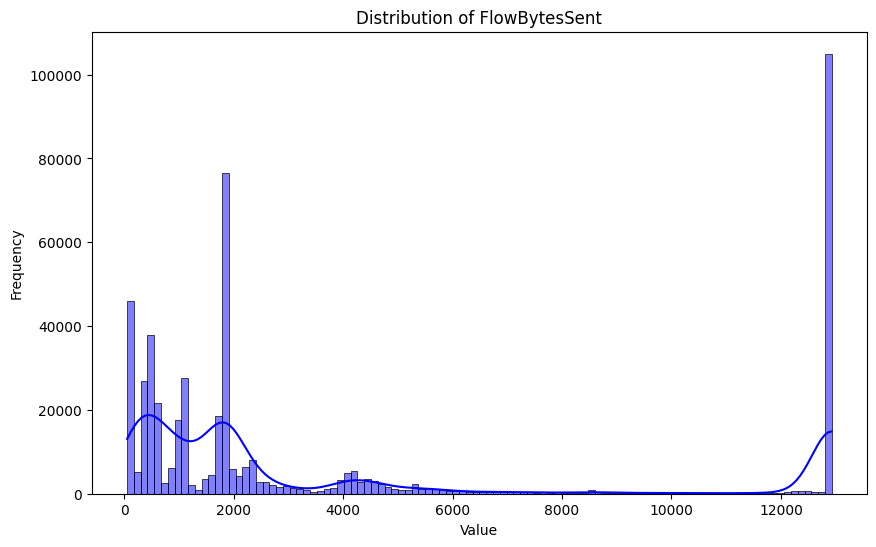

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.histplot(df['FlowBytesSent'], kde=True, color='blue')
plt.title('Distribution of FlowBytesSent')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.show()

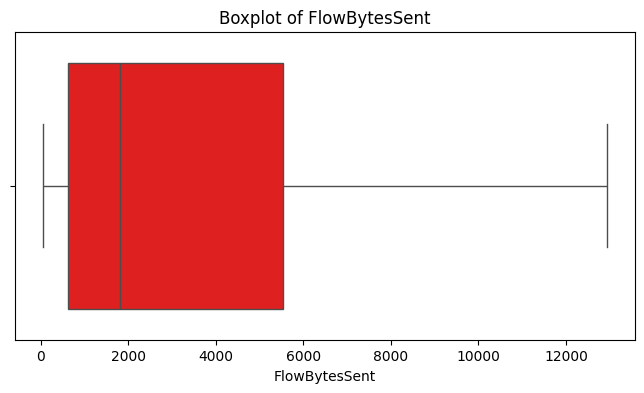

In [ ]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['FlowBytesSent'], color='red')
plt.title('Boxplot of FlowBytesSent')
plt.show()

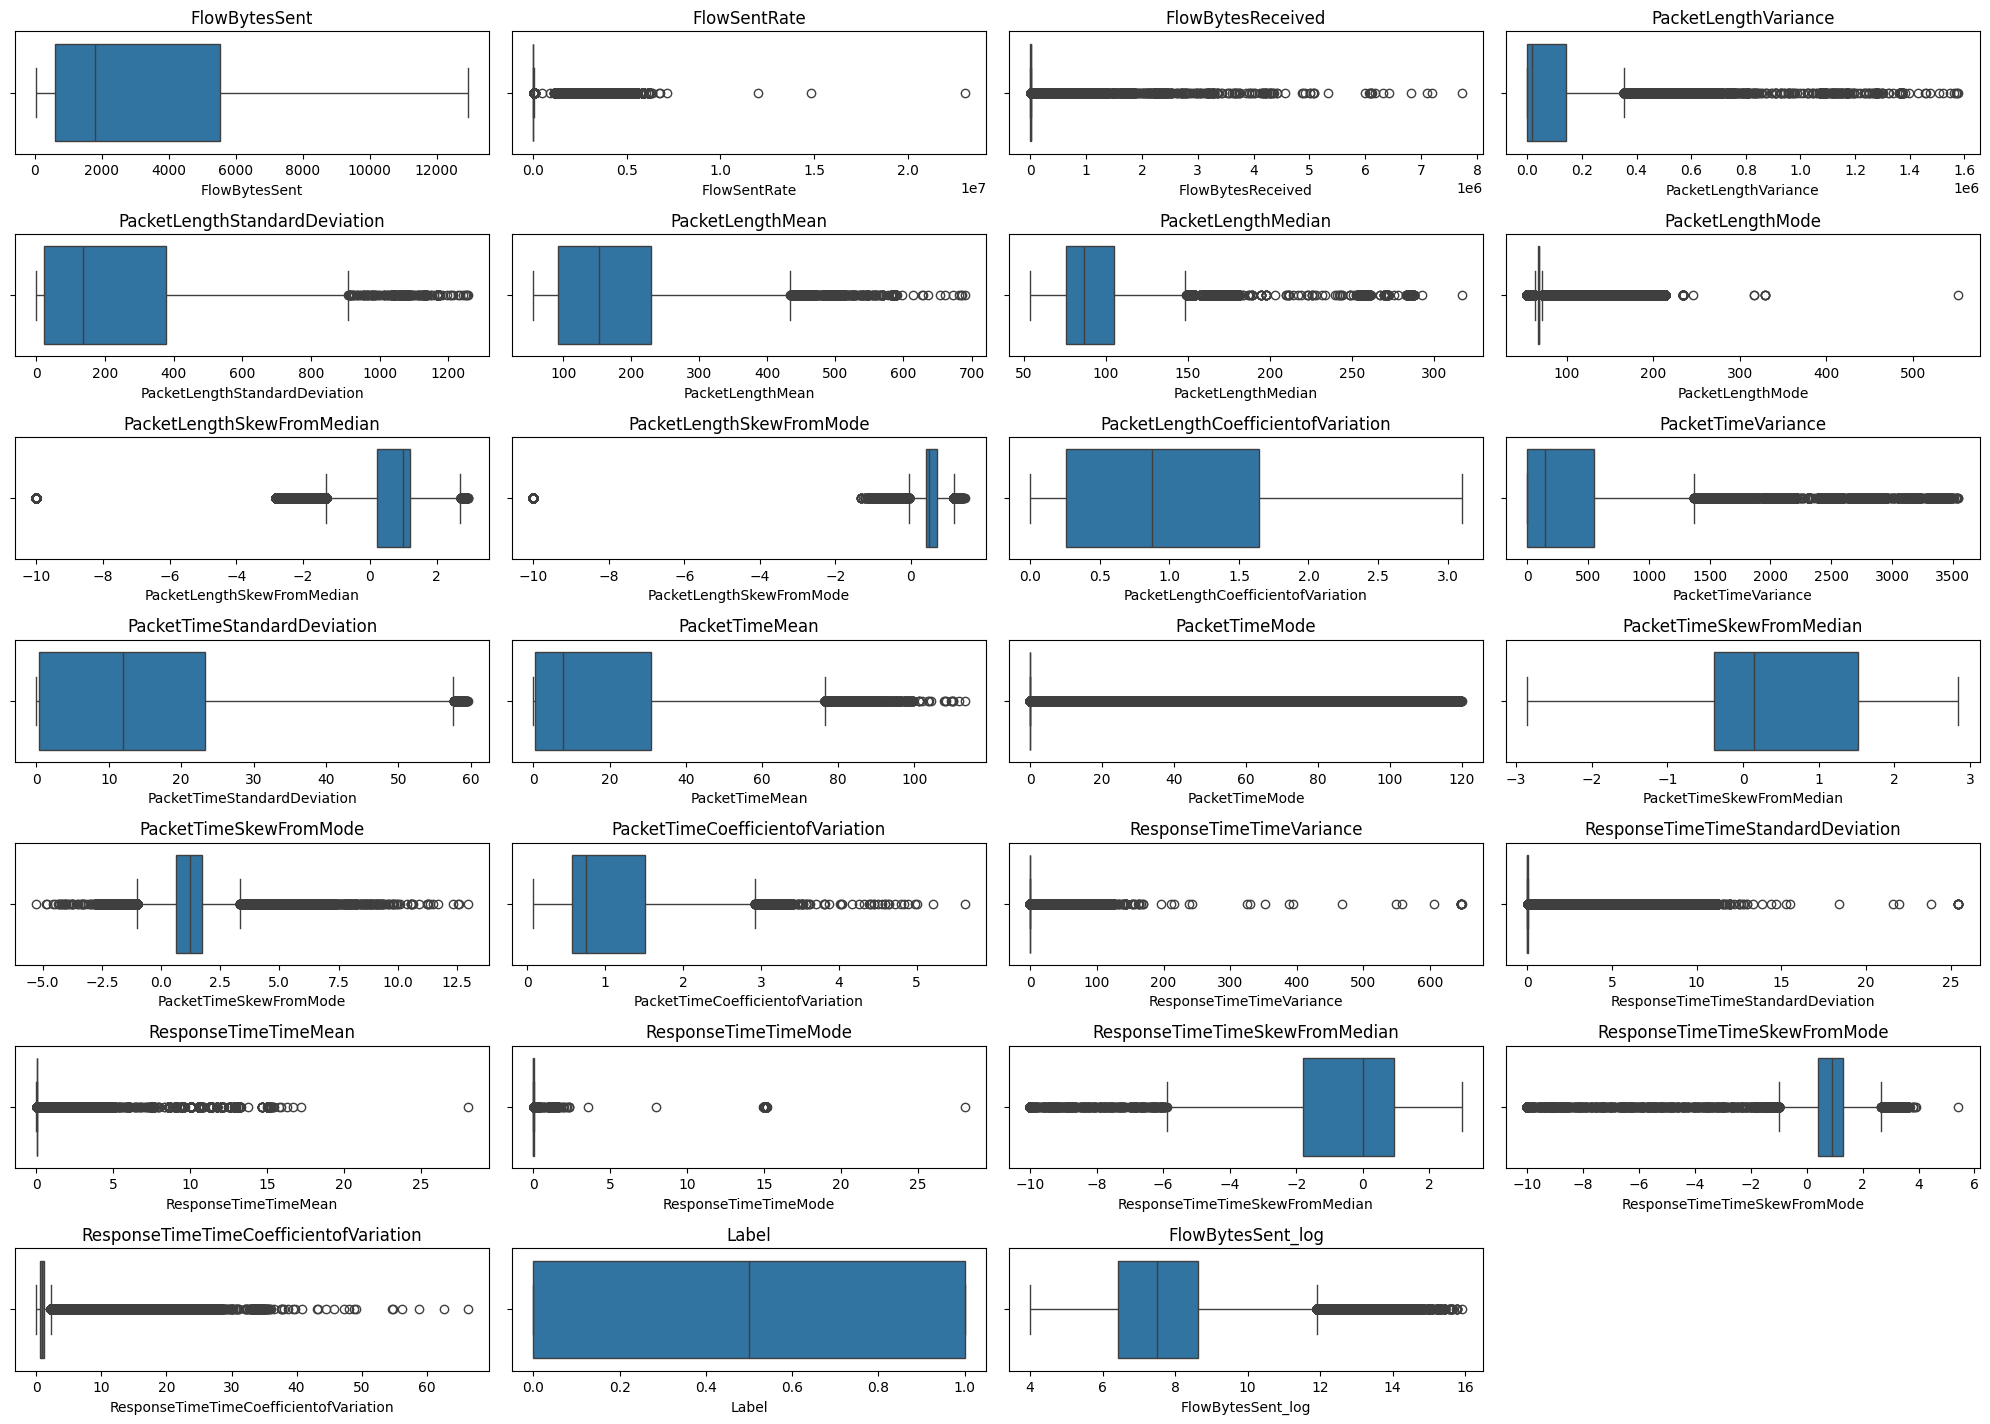

In [ ]:
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns


plt.figure(figsize=(20, 20))
for i, col in enumerate(numeric_cols):
    plt.subplot(10, 4, i+1) # 10 rows, 4 columns ka grid
    sns.boxplot(x=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1079/263572388.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Label', y=feature, data=df, palette='Set2')


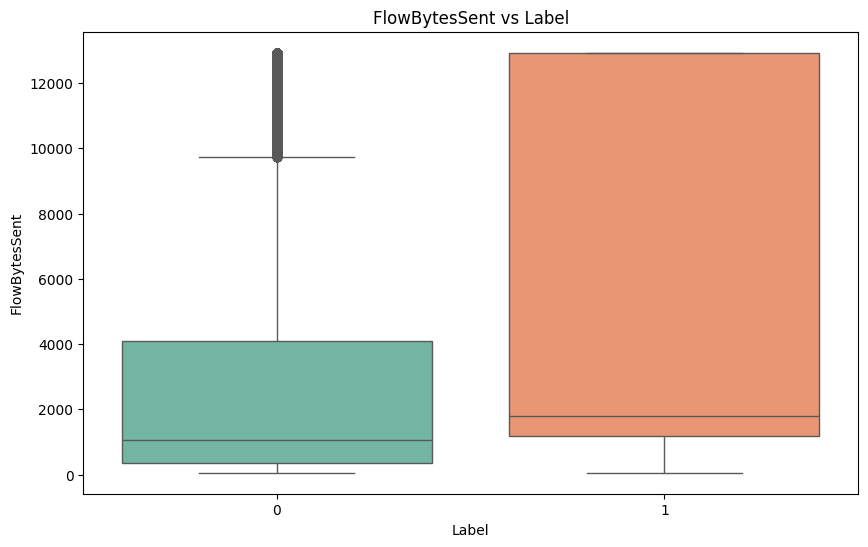

In [ ]:
feature = 'FlowBytesSent'

plt.figure(figsize=(10, 6))
sns.boxplot(x='Label', y=feature, data=df, palette='Set2')
plt.title(f'{feature} vs Label')
plt.show()

In [ ]:
df_numeric = df.copy()
df_numeric['Label'] = df_numeric['Label'].map({'Benign': 0, 'Malicious': 1})

In [ ]:
corr = df_numeric.corr()

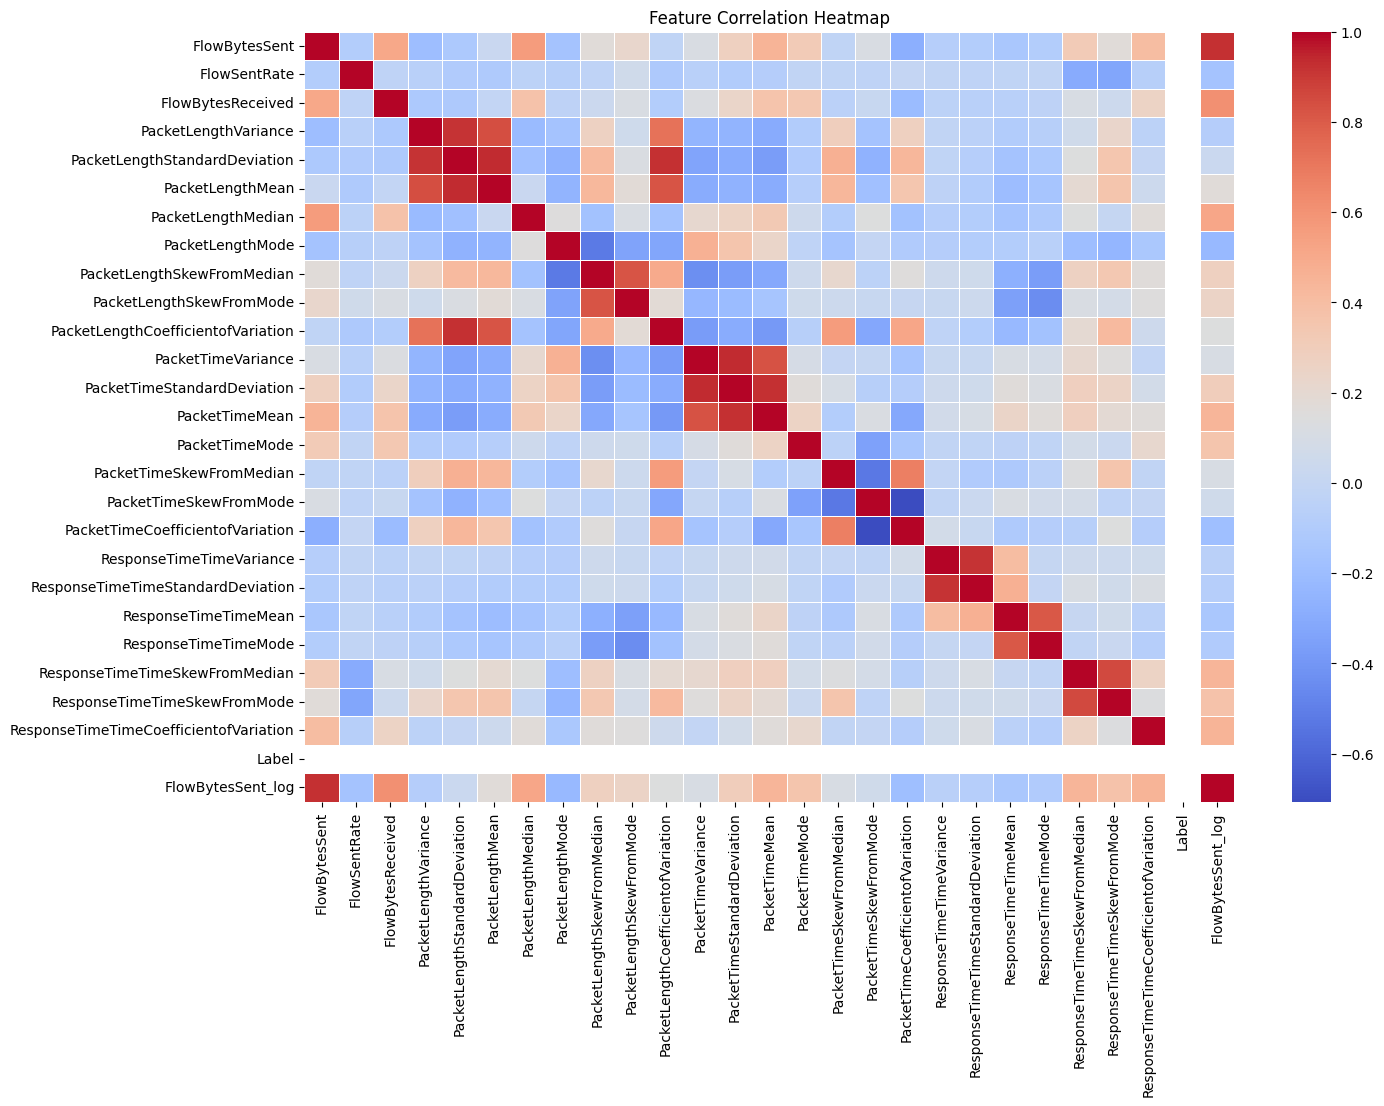

In [ ]:
plt.figure(figsize=(15, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

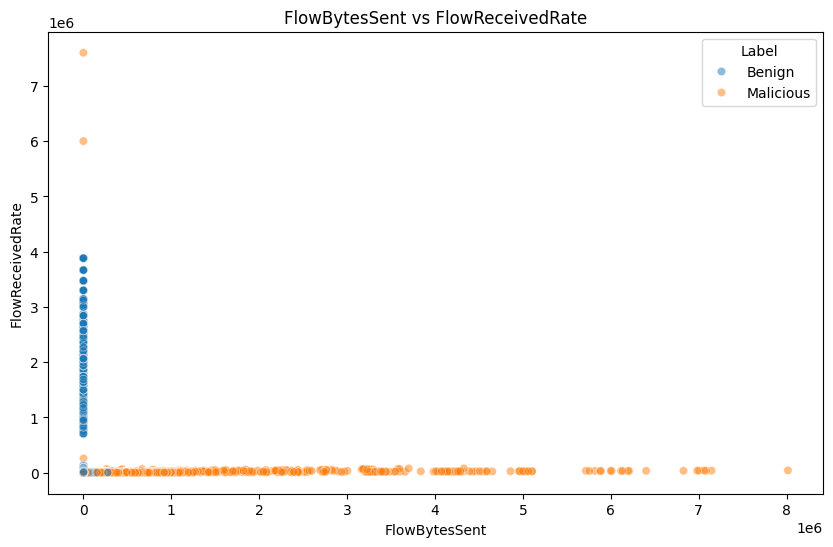

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='FlowBytesSent', y='FlowReceivedRate', hue='Label', data=df_combined, alpha=0.5)
plt.title('FlowBytesSent vs FlowReceivedRate')
plt.show()

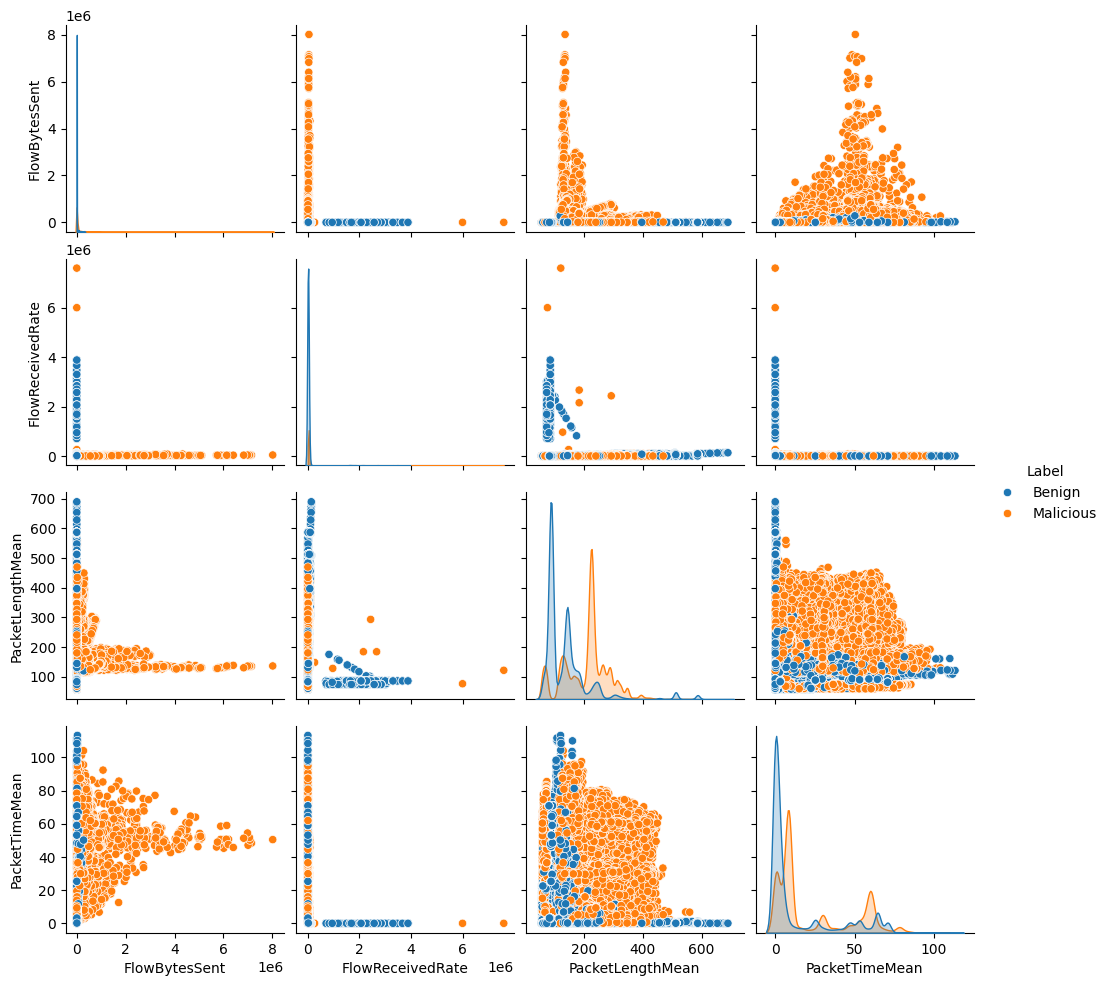

In [ ]:
top_features = ['FlowBytesSent', 'FlowReceivedRate', 'PacketLengthMean', 'PacketTimeMean', 'Label']
sns.pairplot(df_combined[top_features], hue='Label', diag_kind='kde')
plt.show()

In [ ]:
df.dropna()

,FlowBytesSent,FlowSentRate,FlowBytesReceived,PacketLengthVariance,PacketLengthStandardDeviation,PacketLengthMean,PacketLengthMedian,PacketLengthMode,PacketLengthSkewFromMedian,PacketLengthSkewFromMode,...,PacketTimeCoefficientofVariation,ResponseTimeTimeVariance,ResponseTimeTimeStandardDeviation,ResponseTimeTimeMean,ResponseTimeTimeMode,ResponseTimeTimeSkewFromMedian,ResponseTimeTimeSkewFromMode,ResponseTimeTimeCoefficientofVariation,Label,FlowBytesSent_log
0,353.0,80.890348,393,469.209877,21.661253,82.888889,66.0,66,2.339046,0.779682,...,0.534524,1.754601e-09,0.000042,0.000048,0.000017,2.028699,0.737490,0.869641,0,5.866468
1,1807.0,53.056709,4828,145520.370987,381.471324,228.793103,76.0,68,1.201609,0.421508,...,1.591559,5.348911e-05,0.007314,0.011523,0.000016,-1.538407,1.573304,0.634722,1,7.499423
2,12928.0,479.536009,27719,25949.480963,161.088426,135.186709,87.0,87,0.897396,0.299132,...,0.670950,3.356292e-01,0.579335,0.139518,0.000003,0.712241,0.240819,4.152404,1,9.615805
3,1755.0,58.193065,4617,154088.445853,392.541007,245.112953,75.5,54,1.296268,0.486861,...,2.029971,1.245935e+02,11.162146,5.011613,0.012884,1.342708,0.447829,2.227258,0,7.470224
4,618.0,3.491495,315,319.410000,17.872045,93.300000,105.0,105,-1.963961,-0.654654,...,0.816362,2.975575e-09,0.000054,0.015507,0.015466,1.986391,0.751146,0.003502,0,6.426488
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499101,4865.0,144.950072,7622,216676.627229,465.485367,231.240741,149.5,68,0.526810,0.350689,...,1.916871,6.745692e-05,0.008213,0.009261,0.000003,-1.093069,1.127264,0.886816,1,8.489822
499102,1807.0,53.007877,4895,141408.773333,376.043579,223.400000,76.0,68,1.175928,0.413250,...,1.629455,5.509494e-05,0.007423,0.010499,0.000021,-1.938720,1.411665,0.706966,1,7.499423
499103,1738.0,51.137163,4761,322424.727023,567.824557,240.703704,76.0,68,0.870183,0.304150,...,1.515189,5.126219e-05,0.007160,0.012407,0.000011,-1.628476,1.731273,0.577098,1,7.460490
499104,353.0,85.910364,393,469.209877,21.661253,82.888889,66.0,66,2.339046,0.779682,...,0.534526,2.246325e-09,0.000047,0.000051,0.000017,2.089574,0.717636,0.921984,0,5.866468


In [ ]:
stratify=y

In [ ]:
from sklearn.ensemble import RandomForestClassifier
n_estimators = 200
random_state = 42
rf_model = RandomForestClassifier(n_estimators=200,random_state=42)

In [ ]:
rf_model.fit(X_train_scaled,y_train)
print("Model Training Completed Successfully!")

Model Training Completed Successfully!


In [113]:
y_pred = rf_model.predict(X_test_scaled)
print(y_pred[:10])

[1 0 1 1 0 0 0 1 1 0]


In [115]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=200, random_state=42)

In [117]:
from sklearn.metrics import accuracy_score

In [118]:
import os

PROJECT_DIR = "/content/drive/MyDrive/CyberSecurity_Dataset"

os.makedirs(PROJECT_DIR, exist_ok=True)

print("Project folder ready:", PROJECT_DIR)

Project folder ready: /content/drive/MyDrive/CyberSecurity_Dataset


In [119]:
import os

DATA_PATH = os.path.join(PROJECT_DIR, "cleaned_data.parquet")

df.to_parquet(DATA_PATH, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [121]:
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/CyberSecurity_Dataset/BCCC-CIRA-CIC-DoHBrw-2020.csv"

for chunk in pd.read_csv(DATA_PATH, chunksize=50000):
    print(chunk.shape)

    # Yahan chunk-level preprocessing karo
    # Processed chunk ko disk par save kar sakte ho

(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(50000, 29)
(49106, 29)


In [122]:
import gc

del df

gc.collect()

15257250

In [123]:
import pandas as pd

required_columns = [
    "FlowBytesSent",
    "FlowSentRate",
    "FlowBytesReceived",
    "FlowReceivedRate",
    "Label"
]

df = pd.read_csv(
    "/content/drive/MyDrive/CyberSecurity_Dataset/BCCC-CIRA-CIC-DoHBrw-2020.csv",
    usecols=required_columns
)